# Minimum-width minimizer for one AR(3) process at $k=4$

This notebook generates one stationary AR(3) process with innovations $\varepsilon_t\sim\operatorname{Unif}[-1,1]$, constructs only the $k=p+1=4$ sliding-window point cloud, and minimizes its empirical directional width on the unit sphere.

The optimization uses 12 deterministic starts for projected subgradient descent and retains the run with the smallest width. Because width is invariant under $u\mapsto-u$, the reported sign is aligned with the population AR direction $(1,-\phi_1,-\phi_2,-\phi_3)$.

In [1]:
import sys                                                                                          ### INFRASTRUCTURE
import time
from pathlib import Path                                                                            ### INFRASTRUCTURE

import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.spatial.distance import pdist
from scipy.stats import mannwhitneyu, spearmanr

AR_CODE_DIR = next(                                                                                 ### INFRASTRUCTURE
    (                                                                                               ### INFRASTRUCTURE
        candidate.resolve()                                                                         ### INFRASTRUCTURE
        for root in (Path.cwd(), *Path.cwd().parents)                                               ### INFRASTRUCTURE
        for candidate in (root / "Code" / "Code_AR_processes", root)                                ### INFRASTRUCTURE
        if (candidate / "ar_tools/functions.py").is_file()                                          ### INFRASTRUCTURE
    ),                                                                                              ### INFRASTRUCTURE
    None,                                                                                           ### INFRASTRUCTURE
)                                                                                                   ### INFRASTRUCTURE
if AR_CODE_DIR is None:                                                                             ### INFRASTRUCTURE
    raise FileNotFoundError(                                                                        ### INFRASTRUCTURE
        "Could not locate Code/Code_AR_processes from the current directory."                       ### INFRASTRUCTURE
    )                                                                                               ### INFRASTRUCTURE
PROJECT_ROOT = AR_CODE_DIR.parents[1]                                                               ### INFRASTRUCTURE
if str(PROJECT_ROOT) not in sys.path:                                                               ### INFRASTRUCTURE
    sys.path.insert(0, str(PROJECT_ROOT))                                                           ### INFRASTRUCTURE

from Code.Code_AR_processes.ar_tools.descent import (
    batched_geometric_width_curves,
    projected_subgradient_empirical_width,
)
from Code.Code_AR_processes.ar_tools.functions import (
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
)

np.set_printoptions(precision=8, suppress=True)                                                     ### REPORTING

In [2]:
order = 3
embedding_dimension = order + 1
sample_size = 2_000
burnin = 1_000
coefficient_seed = 20260910
process_seed = 20260911

phi = jones_ar_coefficients(order, rng=coefficient_seed)
ar3_series = simulate_uniform_ar(
    phi,
    sample_size=sample_size,
    burnin=burnin,
    half_width=1.0,
    rng=process_seed,
)
point_cloud_k4 = sliding_window_point_cloud(
    ar3_series,
    embedding_dimension=embedding_dimension,
)
point_cloud_diameter = float(pdist(point_cloud_k4).max())

print(f"AR coefficients: {phi}")                                                                    ### REPORTING
print(f"Embedding dimension: k = {embedding_dimension}")                                            ### REPORTING
print(f"Point-cloud shape: {point_cloud_k4.shape}")                                                 ### REPORTING
print(f"Empirical Lipschitz constant L_T: {point_cloud_diameter:.8f}")                              ### REPORTING

AR coefficients: [-1.0201964  -0.40421235 -0.37447885]
Embedding dimension: k = 4
Point-cloud shape: (1997, 4)
Empirical Lipschitz constant L_T: 36.56167325


In [3]:
number_of_starts = 12
optimization_iterations = 5_000
optimizer_seed = 20260912
initial_step_scale = 0.2
initial_step = initial_step_scale / point_cloud_diameter

# Include the smallest-covariance eigenvector and deterministic random starts.
_, covariance_eigenvectors = np.linalg.eigh(
    np.cov(point_cloud_k4, rowvar=False)
)
initial_direction_generator = np.random.default_rng(optimizer_seed)
initial_directions = [covariance_eigenvectors[:, 0]]
initial_directions.extend(
    initial_direction_generator.normal(size=embedding_dimension)
    for _ in range(number_of_starts - 1)
)

descent_results = [
    projected_subgradient_empirical_width(
        point_cloud_k4,
        iterations=optimization_iterations,
        initial_step=initial_step,
        patience=1_200,
        rng=optimizer_seed + start_index,
        initial_direction=initial_direction,
        step_schedule="geometric",
        geometric_decay=0.997,
    )
    for start_index, initial_direction in enumerate(initial_directions)
]

start_minimum_widths = np.array([
    result["minimum_width"] for result in descent_results
])
best_start = int(np.argmin(start_minimum_widths))
best_result = descent_results[best_start]
estimated_minimizer = best_result["direction"].copy()

# Fix the otherwise arbitrary sign of the minimizing direction.
population_ar_direction = np.concatenate(([1.0], -phi))
population_ar_direction /= np.linalg.norm(population_ar_direction)
if estimated_minimizer @ population_ar_direction < 0.0:
    estimated_minimizer *= -1.0

print(f"Initial step eta_0 = 0.2 / L_T: {initial_step:.10f}")                                       ### REPORTING
print(f"Best start: {best_start + 1} of {number_of_starts}")                                        ### REPORTING
print(f"Minimum empirical width: {best_result['minimum_width']:.10f}")                              ### REPORTING
print("Minimizing unit direction u_hat:")                                                           ### REPORTING
print(estimated_minimizer)                                                                          ### REPORTING
print(f"Norm of u_hat: {np.linalg.norm(estimated_minimizer):.10f}")                                 ### REPORTING
print("Population AR direction (diagnostic):")                                                      ### REPORTING
print(population_ar_direction)                                                                      ### REPORTING
print(                                                                                              ### REPORTING
    "Absolute cosine similarity: "                                                                  ### REPORTING
    f"{abs(estimated_minimizer @ population_ar_direction):.10f}"                                    ### REPORTING
)                                                                                                   ### REPORTING

Initial step eta_0 = 0.2 / L_T: 0.0054702092
Best start: 8 of 12
Minimum empirical width: 1.3071979716
Minimizing unit direction u_hat:
[0.64295806 0.66166622 0.28492249 0.26004215]
Norm of u_hat: 1.0000000000
Population AR direction (diagnostic):
[0.65310354 0.66629388 0.26399251 0.24457346]
Absolute cosine similarity: 0.9995991548


## Monte Carlo coefficient-recovery experiment

For each of 50 replications, this experiment independently draws stationary AR(3) coefficients with Jones' method, simulates a length-$2{,}000$ process with $\operatorname{Unif}[-1,1]$ innovations, and estimates the minimum-width direction using only the $k=4$ embedding. The geometric schedule is normalized using the empirical Lipschitz constant

$$L_T=\operatorname{diam}(\mathcal P_4)=\max_{s,t}\lVert Y_s^{(4)}-Y_t^{(4)}\rVert,\qquad \eta_t=\frac{0.2}{L_T}(0.997)^t.$$

The coefficient estimate is

$$\widehat\phi_j=-\frac{\widehat u_j}{\widehat u_0},\qquad j=1,2,3.$$

As a classical benchmark, the same point cloud is fitted by $L^\infty$ (Chebyshev) regression. It solves the linear program

$$\min_{\phi,c,r} r \quad\text{subject to}\quad \left|X_t-\sum_{j=1}^3\phi_jX_{t-j}-c\right|\le r \quad\text{for every }t.$$

This minimizes the unnormalized residual range, whereas the proposed method minimizes directional width over the sphere. The LP is therefore used only as a coefficient-estimation benchmark.

Both methods receive exactly the same coefficient draws and simulated paths. The reported overall MSE is the mean of all squared coefficient errors.


In [4]:
def chebyshev_ar_fit(point_cloud):
    """Fit AR coefficients by minimizing the maximum absolute residual."""
    response = point_cloud[:, 0]
    lagged_values = point_cloud[:, 1:]
    observation_count = len(response)
    ones = np.ones(observation_count)

    # Variables are (phi_1, phi_2, phi_3, residual_center, radius).
    inequality_matrix = np.vstack((
        np.column_stack((-lagged_values, -ones, -ones)),
        np.column_stack((lagged_values, ones, -ones)),
    ))
    inequality_bounds = np.concatenate((-response, response))
    objective = np.zeros(order + 2)
    objective[-1] = 1.0

    result = linprog(
        objective,
        A_ub=inequality_matrix,
        b_ub=inequality_bounds,
        bounds=[(None, None)] * (order + 1) + [(0.0, None)],
        method="highs",
    )
    if not result.success:
        raise RuntimeError(f"Chebyshev LP failed: {result.message}")
    return result.x[:order], result.x[order], result.x[-1]


replication_count = 50
experiment_seed = 20260913
experiment_rows = []

for replication in range(replication_count):
    process_generator = np.random.default_rng(
        np.random.SeedSequence([experiment_seed, replication, 0])
    )
    true_phi = jones_ar_coefficients(order, rng=process_generator)
    replicated_series = simulate_uniform_ar(
        true_phi,
        sample_size=sample_size,
        burnin=burnin,
        half_width=1.0,
        rng=process_generator,
    )
    replicated_point_cloud = sliding_window_point_cloud(
        replicated_series, embedding_dimension=embedding_dimension
    )

    geometric_start_time = time.perf_counter()
    replicated_lipschitz_constant = float(
        pdist(replicated_point_cloud).max()
    )
    replicated_initial_step = (
        initial_step_scale / replicated_lipschitz_constant
    )
    _, replicated_widths, _, replicated_directions = (
        batched_geometric_width_curves(
            replicated_series,
            [embedding_dimension],
            seed=experiment_seed,
            replication=replication,
            starts=number_of_starts,
            iterations=optimization_iterations,
            initial_step=replicated_initial_step,
            geometric_decay=0.997,
            return_directions=True,
        )
    )
    replicated_minimizer = replicated_directions[0]
    if abs(replicated_minimizer[0]) <= np.finfo(float).eps:
        raise RuntimeError(
            f"Cannot recover coefficients in replication {replication + 1}: "
            "the first minimizer component is numerically zero."
        )
    estimated_phi = (
        -replicated_minimizer[1:] / replicated_minimizer[0]
    )
    true_direction = np.concatenate(([1.0], -true_phi))
    true_direction /= np.linalg.norm(true_direction)
    direction_cosine_similarity = abs(replicated_minimizer @ true_direction)
    geometric_runtime = time.perf_counter() - geometric_start_time
    squared_errors = (estimated_phi - true_phi) ** 2

    chebyshev_start_time = time.perf_counter()
    chebyshev_phi, chebyshev_center, chebyshev_radius = (
        chebyshev_ar_fit(replicated_point_cloud)
    )
    chebyshev_runtime = time.perf_counter() - chebyshev_start_time
    chebyshev_squared_errors = (chebyshev_phi - true_phi) ** 2

    row = {
        "replication": replication + 1,
        "minimum_width": replicated_widths[0],
        "coefficient_mse": float(np.mean(squared_errors)),
        "lipschitz_constant": replicated_lipschitz_constant,
        "initial_step": replicated_initial_step,
        "abs_u_0": abs(replicated_minimizer[0]),
        "geometric_runtime_seconds": geometric_runtime,
        "direction_cosine_similarity": direction_cosine_similarity,
        "chebyshev_coefficient_mse": float(
            np.mean(chebyshev_squared_errors)
        ),
        "chebyshev_residual_center": chebyshev_center,
        "chebyshev_residual_radius": chebyshev_radius,
        "chebyshev_runtime_seconds": chebyshev_runtime,
    }
    for coefficient_index in range(order):
        suffix = coefficient_index + 1
        row[f"true_phi_{suffix}"] = true_phi[coefficient_index]
        row[f"estimated_phi_{suffix}"] = estimated_phi[coefficient_index]
        row[f"squared_error_phi_{suffix}"] = squared_errors[coefficient_index]
        row[f"chebyshev_phi_{suffix}"] = chebyshev_phi[coefficient_index]
        row[f"chebyshev_squared_error_phi_{suffix}"] = (
            chebyshev_squared_errors[coefficient_index]
        )
    experiment_rows.append(row)

    if (replication + 1) % 10 == 0:                                                                 ### REPORTING
        print(f"Completed {replication + 1}/{replication_count} processes")                         ### REPORTING

ar3_mse_results = pd.DataFrame(experiment_rows)

Completed 10/50 processes
Completed 20/50 processes
Completed 30/50 processes
Completed 40/50 processes
Completed 50/50 processes


In [5]:
squared_error_columns = [
    f"squared_error_phi_{index}" for index in range(1, order + 1)
]
chebyshev_squared_error_columns = [
    f"chebyshev_squared_error_phi_{index}"
    for index in range(1, order + 1)
]
method_columns = {
    "Minimum width": {
        "process_mse": "coefficient_mse",
        "squared_errors": squared_error_columns,
        "runtime": "geometric_runtime_seconds",
    },
    "LP Chebyshev": {
        "process_mse": "chebyshev_coefficient_mse",
        "squared_errors": chebyshev_squared_error_columns,
        "runtime": "chebyshev_runtime_seconds",
    },
}
comparison_rows = []
for method, columns in method_columns.items():
    process_mse = ar3_mse_results[columns["process_mse"]]
    comparison_rows.append({
        "method": method,
        "overall_coefficient_mse": float(
            ar3_mse_results[columns["squared_errors"]].to_numpy().mean()
        ),
        "median_process_mse": float(process_mse.median()),
        "maximum_process_mse": float(process_mse.max()),
        "failures_mse_above_1": int((process_mse > 1.0).sum()),
        "mean_runtime_seconds": float(
            ar3_mse_results[columns["runtime"]].mean()
        ),
    })
comparison_summary = pd.DataFrame(comparison_rows).set_index("method")

mse_by_coefficient = pd.DataFrame(
    {
        method: [
            ar3_mse_results[column].mean()
            for column in columns["squared_errors"]
        ]
        for method, columns in method_columns.items()
    },
    index=[f"phi_{index}" for index in range(1, order + 1)],
)
lp_win_count = int(
    (
        ar3_mse_results["chebyshev_coefficient_mse"]
        < ar3_mse_results["coefficient_mse"]
    ).sum()
)

print("Paired comparison on the same 50 processes:")                                                ### REPORTING
print(comparison_summary.to_string())                                                               ### REPORTING
print(f"\nLP Chebyshev has lower process MSE in {lp_win_count}/50 runs.")                           ### REPORTING
print(                                                                                              ### REPORTING
    "L_T range: "                                                                                   ### REPORTING
    f"{ar3_mse_results['lipschitz_constant'].min():.6f} to "                                        ### REPORTING
    f"{ar3_mse_results['lipschitz_constant'].max():.6f}"                                            ### REPORTING
)                                                                                                   ### REPORTING
print(                                                                                              ### REPORTING
    "eta_0 range: "                                                                                 ### REPORTING
    f"{ar3_mse_results['initial_step'].min():.8f} to "                                              ### REPORTING
    f"{ar3_mse_results['initial_step'].max():.8f}"                                                  ### REPORTING
)                                                                                                   ### REPORTING
print("MSE by coefficient and method:")                                                             ### REPORTING
print(mse_by_coefficient.to_string())                                                               ### REPORTING

ar3_mse_results                                                                                     ### REPORTING

Paired comparison on the same 50 processes:
               overall_coefficient_mse  median_process_mse  maximum_process_mse  failures_mse_above_1  mean_runtime_seconds
method                                                                                                                     
Minimum width               192.218620            0.000015          8128.038271                     3              0.733098
LP Chebyshev                  0.000007            0.000002             0.000079                     0              0.012228

LP Chebyshev has lower process MSE in 35/50 runs.
L_T range: 3.718168 to 74.283141
eta_0 range: 0.00269240 to 0.05378993
MSE by coefficient and method:
       Minimum width  LP Chebyshev
phi_1     242.980478      0.000006
phi_2     311.502616      0.000010
phi_3      22.172765      0.000006


,replication,minimum_width,coefficient_mse,lipschitz_constant,initial_step,abs_u_0,geometric_runtime_seconds,direction_cosine_similarity,chebyshev_coefficient_mse,chebyshev_residual_center,...,true_phi_2,estimated_phi_2,squared_error_phi_2,chebyshev_phi_2,chebyshev_squared_error_phi_2,true_phi_3,estimated_phi_3,squared_error_phi_3,chebyshev_phi_3,chebyshev_squared_error_phi_3
0,1,1.177275,8.872332e-05,10.059324,0.019882,0.587373,0.854944,0.999979,1.007232e-06,-0.000520,...,-0.979222,-0.986263,4.956978e-05,-0.979864,4.123188e-07,-0.493102,-0.504154,1.221357e-04,-0.494075,9.454742e-07
1,2,1.487487,7.709350e-06,12.080760,0.016555,0.745491,1.124589,0.999995,1.618911e-07,-0.001357,...,0.018752,0.022294,1.254141e-05,0.019370,3.820303e-07,-0.890328,-0.893467,9.853411e-06,-0.890377,2.363545e-09
2,3,0.719715,4.438976e-05,74.283141,0.002692,0.359756,0.705252,0.999999,1.948203e-06,0.000790,...,-1.651957,-1.661067,8.300782e-05,-1.650039,3.676569e-06,-0.859893,-0.862644,7.570040e-06,-0.858453,2.073109e-06
3,4,1.370186,4.259806e-07,14.216242,0.014068,0.686749,0.673074,1.000000,4.259803e-07,-0.001142,...,0.317997,0.318464,2.184264e-07,0.318464,2.184269e-07,0.788173,0.789198,1.052060e-06,0.789198,1.052059e-06
4,5,1.144106,1.197899e-05,41.815389,0.004783,0.572230,0.673331,0.999995,1.135453e-06,-0.000089,...,-0.149417,-0.154095,2.188609e-05,-0.147939,2.184595e-06,0.316625,0.314626,3.998336e-06,0.317533,8.231402e-07
5,6,1.827953,3.814957e-06,6.272393,0.031886,0.916781,0.668987,0.999995,3.814973e-06,-0.002251,...,0.086655,0.086738,6.952116e-09,0.086738,6.953001e-09,-0.410881,-0.410302,3.345272e-07,-0.410302,3.345366e-07
6,7,1.517034,4.439854e-06,9.226494,0.021677,0.759681,0.744415,0.999997,4.439860e-06,-0.001271,...,-0.246910,-0.250331,1.170696e-05,-0.250331,1.170698e-05,0.676632,0.677887,1.575305e-06,0.677887,1.575309e-06
7,8,0.888976,3.111760e-04,29.840818,0.006702,0.440888,0.687688,0.999970,1.521387e-06,-0.000199,...,-1.071271,-1.095762,5.997914e-04,-1.072889,2.616984e-06,0.385394,0.394496,8.284325e-05,0.386416,1.045111e-06
8,9,1.725373,4.924351e-08,8.521748,0.023469,0.863076,0.672597,1.000000,1.842384e-07,-0.000016,...,0.532543,0.532412,1.721405e-08,0.532004,2.911118e-07,0.219208,0.219340,1.737532e-08,0.218707,2.508543e-07
9,10,1.261455,6.327601e-05,6.837596,0.029250,0.630251,0.774363,0.999983,4.053467e-07,-0.000436,...,-0.809563,-0.819286,9.453430e-05,-0.810406,7.102910e-07,0.406447,0.413900,5.554887e-05,0.407102,4.296196e-07


## When does minimum width beat LP Chebyshev?

The following is an exploratory paired analysis. The three minimum-width runs with MSE above one are excluded when comparing regular parameter regimes, because they represent convergence to the shifted-direction basin rather than ordinary estimator variation. A nominal win means lower process-level coefficient MSE on the same simulated path. Since several quantities are examined on only 47 regular runs, the $p$-values are descriptive rather than confirmatory.

In [6]:
pattern_results = ar3_mse_results.copy()
pattern_results["minimum_width_wins"] = (
    pattern_results["coefficient_mse"]
    < pattern_results["chebyshev_coefficient_mse"]
)
pattern_results["geometric_failure"] = (
    pattern_results["coefficient_mse"] > 1.0
)
for coefficient_index in range(1, order + 1):
    pattern_results[f"abs_phi_{coefficient_index}"] = abs(
        pattern_results[f"true_phi_{coefficient_index}"]
    )
pattern_results["phi_norm"] = np.sqrt(
    sum(
        pattern_results[f"true_phi_{index}"] ** 2
        for index in range(1, order + 1)
    )
)
pattern_results["true_u_0"] = 1.0 / np.sqrt(
    1.0 + pattern_results["phi_norm"] ** 2
)
pattern_results["direction_error"] = (
    1.0 - pattern_results["direction_cosine_similarity"]
)
pattern_results["log10_relative_advantage"] = np.log10(
    pattern_results["chebyshev_coefficient_mse"]
    / pattern_results["coefficient_mse"]
)

def stationarity_root_margin(row):
    coefficients = np.array([
        row[f"true_phi_{index}"] for index in range(1, order + 1)
    ])
    roots = np.roots(np.concatenate((-coefficients[::-1], [1.0])))
    return float(np.min(abs(roots)) - 1.0)


pattern_results["root_margin"] = pattern_results.apply(
    stationarity_root_margin, axis=1
)
regular_results = pattern_results.loc[
    ~pattern_results["geometric_failure"]
].copy()
winning_results = regular_results.loc[
    regular_results["minimum_width_wins"]
]
losing_results = regular_results.loc[
    ~regular_results["minimum_width_wins"]
]

metric_columns = {
    "|phi_1|": "abs_phi_1",
    "|phi_2|": "abs_phi_2",
    "|phi_3|": "abs_phi_3",
    "||phi||": "phi_norm",
    "true |u_0|": "true_u_0",
    "direction error (1-cosine)": "direction_error",
    "stationarity root margin": "root_margin",
    "L_T": "lipschitz_constant",
}
metric_rows = []
correlation_rows = []
for label, column in metric_columns.items():
    win_values = winning_results[column]
    loss_values = losing_results[column]
    rank_test = mannwhitneyu(
        win_values, loss_values, alternative="two-sided"
    )
    rank_biserial = (
        2.0 * rank_test.statistic / (len(win_values) * len(loss_values))
        - 1.0
    )
    metric_rows.append({
        "metric": label,
        "win_median": float(win_values.median()),
        "loss_median": float(loss_values.median()),
        "rank_biserial_effect": float(rank_biserial),
        "exploratory_p_value": float(rank_test.pvalue),
    })
    rank_correlation = spearmanr(
        regular_results[column],
        regular_results["log10_relative_advantage"],
    )
    correlation_rows.append({
        "metric": label,
        "spearman_rho_with_advantage": float(rank_correlation.statistic),
        "exploratory_p_value": float(rank_correlation.pvalue),
    })

win_pattern_summary = pd.DataFrame(metric_rows).set_index("metric")
advantage_correlations = pd.DataFrame(correlation_rows).set_index("metric")
relative_advantage = (
    pattern_results["chebyshev_coefficient_mse"]
    / pattern_results["coefficient_mse"]
)

print(f"Nominal minimum-width wins: {int(pattern_results['minimum_width_wins'].sum())}/50")         ### REPORTING
print(f"Wins by more than 10%: {int((relative_advantage > 1.1).sum())}/50")                         ### REPORTING
print(f"Wins by a factor above 2: {int((relative_advantage > 2.0).sum())}/50")                      ### REPORTING
print("\nMedian characteristics of regular wins and losses:")                                       ### REPORTING
print(win_pattern_summary.to_string())                                                              ### REPORTING
print("\nRank correlations with log10(LP MSE / minimum-width MSE):")                                ### REPORTING
print(advantage_correlations.to_string())                                                           ### REPORTING


Nominal minimum-width wins: 15/50
Wins by more than 10%: 10/50
Wins by a factor above 2: 4/50

Median characteristics of regular wins and losses:
                            win_median  loss_median  rank_biserial_effect  exploratory_p_value
metric                                                                                        
|phi_1|                       0.457863     0.673217             -0.429167             0.019323
|phi_2|                       0.345906     0.477011             -0.266667             0.147287
|phi_3|                       0.563684     0.351348              0.366667             0.045835
||phi||                       0.854127     0.987012             -0.279167             0.129103
true |u_0|                    0.760389     0.712143              0.279167             0.129103
direction error (1-cosine)    0.000001     0.000014             -0.629167             0.000593
stationarity root margin      0.080322     0.112333             -0.304167             0.098010

## Four-method coefficient comparison for known AR order

This section is self-contained: run the setup cell below, then run the experiment cell. It draws 100 independent causal AR($p$) coefficient vectors for each $p=1,\ldots,5$ using `jones_ar_coefficients`. Each process has 2,000 retained observations after a 1,000-step burn-in and independent $\operatorname{Unif}[-1,1]$ innovations. All four methods use the same realization and the known order $p$ in each replication.

OLS minimizes squared residuals without an intercept; Yule-Walker solves the empirical autocovariance equations after subtracting the sample mean; Horváth's $L_\infty$ linear program minimizes the largest absolute residual without an intercept, as written in Section~\ref{sec:classical_estimation_methods}. Minimum width uses the $k=p+1$ embedding and the same 12-start, 5,000-iteration geometric descent settings as the AR(3) experiment above. For each order and method, the reported score is

$$\operatorname{MAE}_p=\frac{1}{100}\sum_{l=1}^{100}\left\|\widehat\phi^{(l)}-\phi^{(l)}\right\|_1.$$

Every replication contributes to the score, including large estimation errors. The experiment cell saves per-process estimates and the summary table under `outputs/csv/ar3_minimum_width_k4/four_method_comparison/` when you run it.

In [7]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import linprog
from scipy.spatial.distance import pdist

# Resolve imports independently of the earlier, computationally expensive cells.
AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (root / "Code" / "Code_AR_processes", root)
        if (candidate / "ar_tools/functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Code.Code_AR_processes.ar_tools.descent import batched_geometric_width_curves
from Code.Code_AR_processes.ar_tools.functions import (
    jones_ar_coefficients,
    simulate_uniform_ar,
    sliding_window_point_cloud,
)


def fit_ols_known_order(point_cloud):
    response = point_cloud[:, 0]
    lagged_values = point_cloud[:, 1:]
    coefficients, _, _, _ = np.linalg.lstsq(lagged_values, response, rcond=None)
    return coefficients


def fit_yule_walker_known_order(series, order):
    centered = np.asarray(series, dtype=float) - np.mean(series)
    observation_count = len(centered)
    autocovariances = np.array([
        centered[lag:] @ centered[:observation_count - lag] / observation_count
        for lag in range(order + 1)
    ])
    lag_indices = np.arange(order)
    autocovariance_matrix = autocovariances[
        np.abs(lag_indices[:, None] - lag_indices[None, :])
    ]
    return np.linalg.solve(autocovariance_matrix, autocovariances[1:])


def fit_horvath_known_order(point_cloud):
    response = point_cloud[:, 0]
    lagged_values = point_cloud[:, 1:]
    order = lagged_values.shape[1]
    minus_radius = -np.ones((len(response), 1))
    inequalities = np.vstack((
        np.column_stack((-lagged_values, minus_radius)),
        np.column_stack((lagged_values, minus_radius)),
    ))
    bounds = np.concatenate((-response, response))
    objective = np.r_[np.zeros(order), 1.0]
    solution = linprog(
        objective,
        A_ub=inequalities,
        b_ub=bounds,
        bounds=[(None, None)] * order + [(0.0, None)],
        method="highs",
    )
    if not solution.success:
        raise RuntimeError(f"Horváth LP failed: {solution.message}")
    return solution.x[:order]


def fit_minimum_width_known_order(series, point_cloud, order, *, seed, replication,
                                  starts, iterations, step_scale, decay):
    diameter = float(pdist(point_cloud).max())
    if not np.isfinite(diameter) or diameter <= 0.0:
        raise RuntimeError("Cannot normalize the minimum-width step: invalid diameter.")
    _, _, _, directions = batched_geometric_width_curves(
        series,
        [order + 1],
        seed=seed,
        replication=replication,
        starts=starts,
        iterations=iterations,
        initial_step=step_scale / diameter,
        geometric_decay=decay,
        return_directions=True,
    )
    direction = directions[0]
    if abs(direction[0]) <= np.finfo(float).eps:
        raise RuntimeError("Cannot recover coefficients: first direction component is zero.")
    return -direction[1:] / direction[0]


In [8]:
comparison_config = {
    "orders": [1, 2, 3, 4, 5],
    "replications_per_order": 100,
    "sample_size": 2_000,
    "burnin": 1_000,
    "innovation_half_width": 1.0,
    "seed": 20260923,
    "minimum_width_starts": 12,
    "minimum_width_iterations": 5_000,
    "minimum_width_step_scale": 0.2,
    "minimum_width_geometric_decay": 0.997,
}
method_names = ["OLS (L2)", "Yule-Walker", "Horváth (L∞)", "Minimum width"]
comparison_rows = []

for true_order in comparison_config["orders"]:
    for replication in range(comparison_config["replications_per_order"]):
        coefficient_rng = np.random.default_rng(np.random.SeedSequence([
            comparison_config["seed"], true_order, replication, 0,
        ]))
        innovation_rng = np.random.default_rng(np.random.SeedSequence([
            comparison_config["seed"], true_order, replication, 1,
        ]))
        true_phi = jones_ar_coefficients(true_order, rng=coefficient_rng)
        series = simulate_uniform_ar(
            true_phi,
            sample_size=comparison_config["sample_size"],
            burnin=comparison_config["burnin"],
            half_width=comparison_config["innovation_half_width"],
            rng=innovation_rng,
        )
        point_cloud = sliding_window_point_cloud(series, true_order + 1)
        estimates = {
            "OLS (L2)": fit_ols_known_order(point_cloud),
            "Yule-Walker": fit_yule_walker_known_order(series, true_order),
            "Horváth (L∞)": fit_horvath_known_order(point_cloud),
            "Minimum width": fit_minimum_width_known_order(
                series,
                point_cloud,
                true_order,
                seed=comparison_config["seed"],
                replication=100 * true_order + replication,
                starts=comparison_config["minimum_width_starts"],
                iterations=comparison_config["minimum_width_iterations"],
                step_scale=comparison_config["minimum_width_step_scale"],
                decay=comparison_config["minimum_width_geometric_decay"],
            ),
        }
        for method in method_names:
            estimated_phi = np.asarray(estimates[method], dtype=float)
            if estimated_phi.shape != true_phi.shape or not np.all(np.isfinite(estimated_phi)):
                raise RuntimeError(
                    f"Invalid {method} estimate for AR({true_order}), "
                    f"replication {replication + 1}."
                )
            absolute_errors = np.abs(estimated_phi - true_phi)
            row = {
                "order": true_order,
                "replication": replication + 1,
                "method": method,
                "l1_error": float(absolute_errors.sum()),
            }
            for coefficient_index in range(true_order):
                suffix = coefficient_index + 1
                row[f"true_phi_{suffix}"] = true_phi[coefficient_index]
                row[f"estimated_phi_{suffix}"] = estimated_phi[coefficient_index]
                row[f"absolute_error_phi_{suffix}"] = absolute_errors[coefficient_index]
            comparison_rows.append(row)

        if (replication + 1) % 10 == 0:
            print(f"AR({true_order}): {replication + 1}/100 processes complete")

coefficient_comparison_results = pd.DataFrame(comparison_rows)
coefficient_comparison_summary = (
    coefficient_comparison_results
    .groupby(["order", "method"], as_index=False)
    .agg(MAE=("l1_error", "mean"), process_count=("l1_error", "size"))
)
assert (coefficient_comparison_summary["process_count"] == 100).all()
coefficient_comparison_table = (
    coefficient_comparison_summary
    .pivot(index="order", columns="method", values="MAE")
    .reindex(index=comparison_config["orders"], columns=method_names)
)

comparison_output_dir = (
    AR_CODE_DIR / "outputs" / "csv" / "ar3_minimum_width_k4" / "four_method_comparison"
)
comparison_output_dir.mkdir(parents=True, exist_ok=True)
coefficient_comparison_results.to_csv(
    comparison_output_dir / "per_process_estimates.csv", index=False
)
coefficient_comparison_summary.to_csv(
    comparison_output_dir / "mae_summary.csv", index=False
)
with (comparison_output_dir / "configuration.json").open("w") as config_file:
    json.dump(comparison_config, config_file, indent=2)

print("MAE = mean over 100 processes of the L1 coefficient error")
print(coefficient_comparison_table.to_string(float_format=lambda value: f"{value:.6f}"))
print(f"Saved results to {comparison_output_dir}")


AR(1): 10/100 processes complete
AR(1): 20/100 processes complete
AR(1): 30/100 processes complete
AR(1): 40/100 processes complete
AR(1): 50/100 processes complete
AR(1): 60/100 processes complete
AR(1): 70/100 processes complete
AR(1): 80/100 processes complete
AR(1): 90/100 processes complete
AR(1): 100/100 processes complete
AR(2): 10/100 processes complete
AR(2): 20/100 processes complete
AR(2): 30/100 processes complete
AR(2): 40/100 processes complete
AR(2): 50/100 processes complete
AR(2): 60/100 processes complete
AR(2): 70/100 processes complete
AR(2): 80/100 processes complete
AR(2): 90/100 processes complete
AR(2): 100/100 processes complete
AR(3): 10/100 processes complete
AR(3): 20/100 processes complete
AR(3): 30/100 processes complete
AR(3): 40/100 processes complete
AR(3): 50/100 processes complete
AR(3): 60/100 processes complete
AR(3): 70/100 processes complete
AR(3): 80/100 processes complete
AR(3): 90/100 processes complete
AR(3): 100/100 processes complete
AR(4): 

## Mean and median coefficient error versus AR order

The two panels compare all four known-order estimators for $p=1,\ldots,5$. Each point summarizes the same 100 simulated processes for its order. The vertical axes are logarithmic so that both the typical errors and the large, unfiltered minimum-width means remain visible. The plotting cell reads the saved experiment CSV files directly; it does not rerun the simulation.

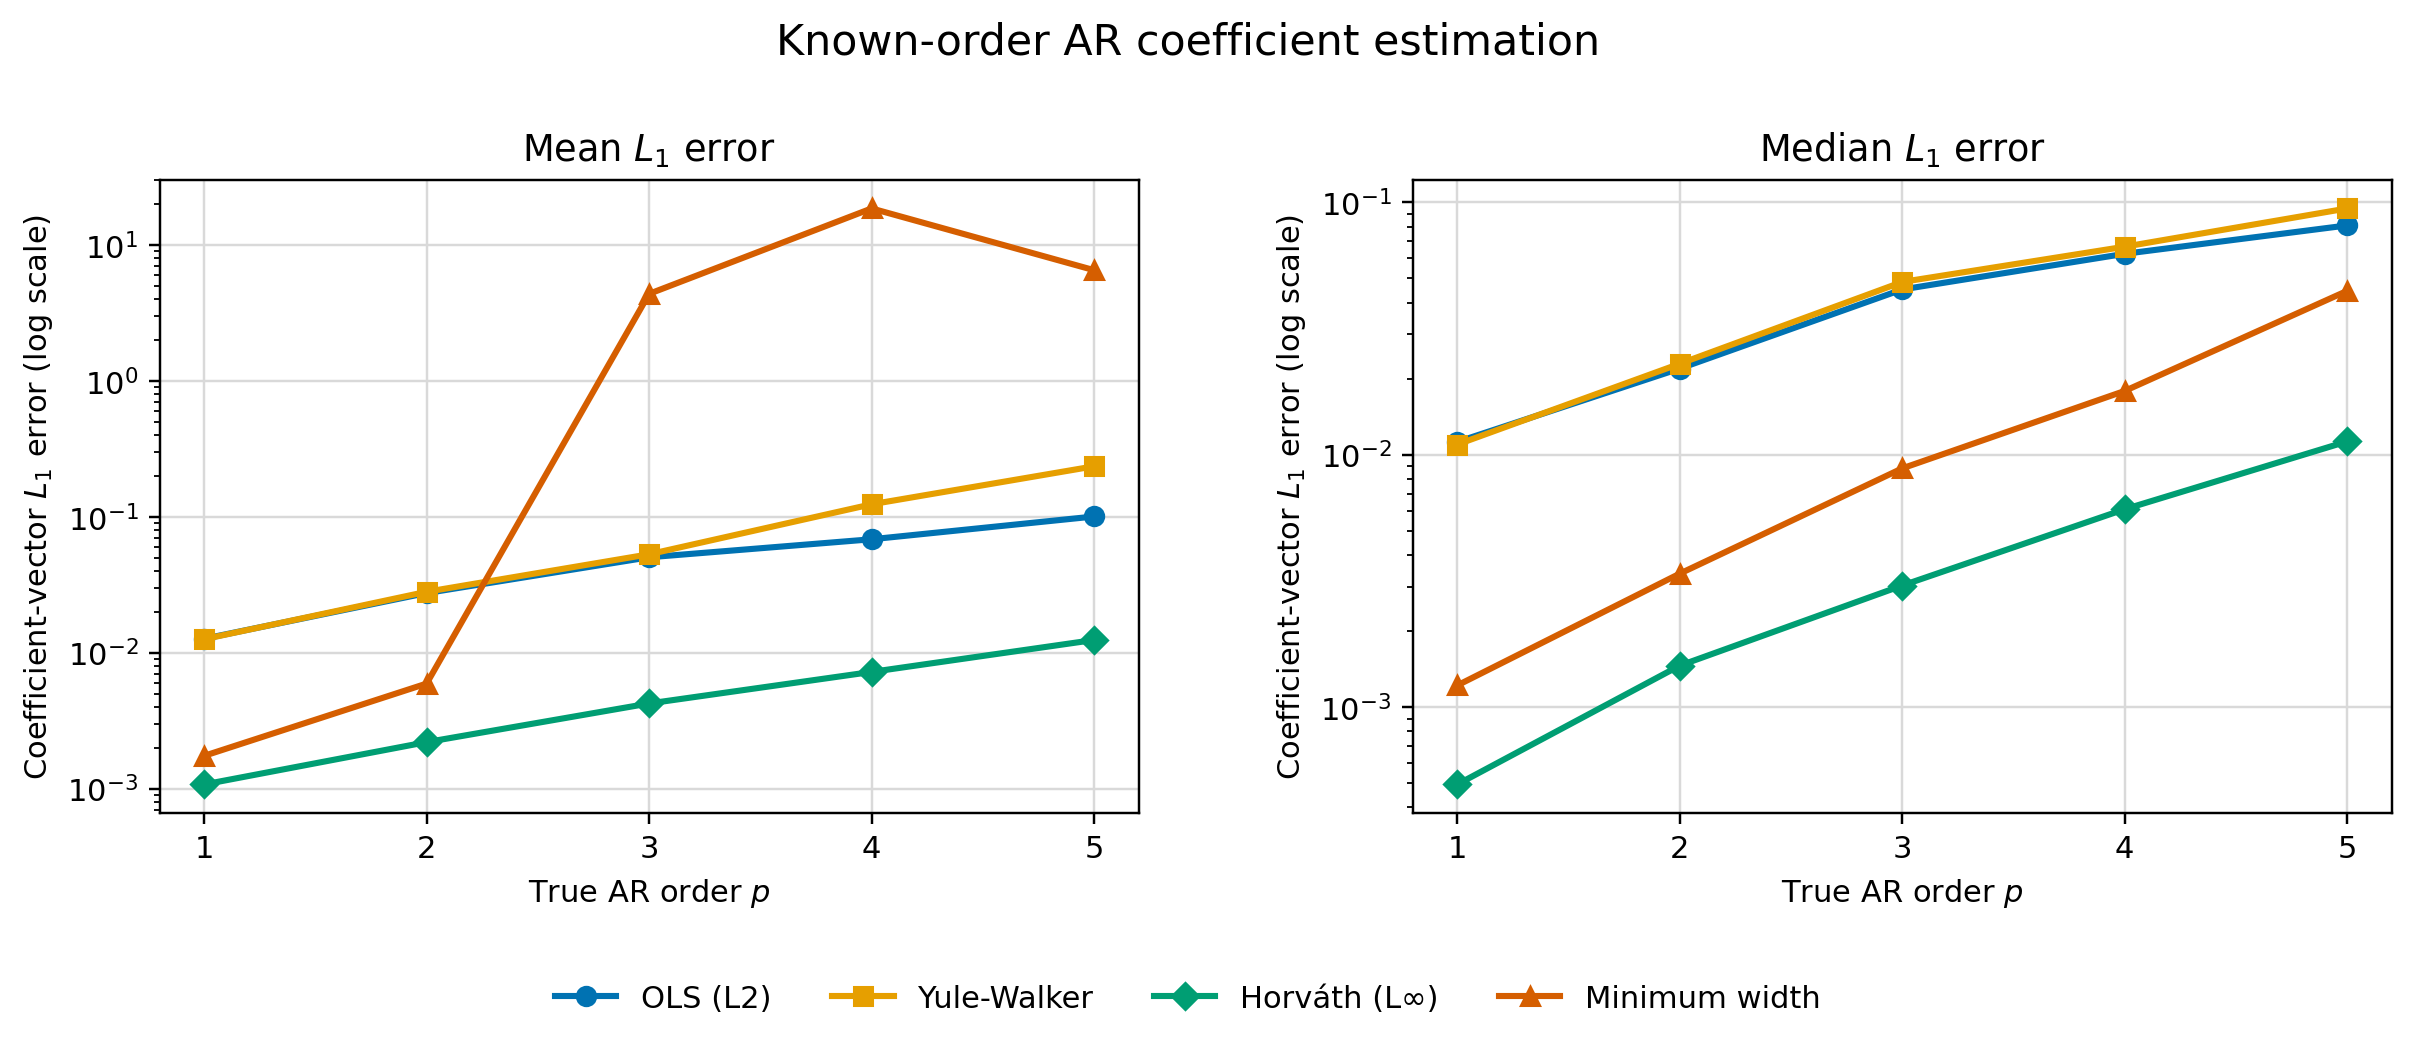

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Read the completed experiment; no simulation or fitting is run here.
comparison_data_dir = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            root / "Code" / "Code_AR_processes" / "outputs" / "csv"
            / "ar3_minimum_width_k4" / "four_method_comparison",
            root / "outputs" / "csv" / "ar3_minimum_width_k4"
            / "four_method_comparison",
        )
        if (candidate / "mae_summary.csv").is_file()
        and (candidate / "per_process_estimates.csv").is_file()
    ),
    None,
)
if comparison_data_dir is None:
    raise FileNotFoundError("Run the four-method experiment before plotting.")

mean_results = pd.read_csv(comparison_data_dir / "mae_summary.csv")
per_process_results = pd.read_csv(comparison_data_dir / "per_process_estimates.csv")
median_results = (
    per_process_results.groupby(["order", "method"], as_index=False)
    .agg(median_error=("l1_error", "median"), process_count=("l1_error", "size"))
)
plot_results = mean_results.merge(
    median_results,
    on=["order", "method", "process_count"],
    validate="one_to_one",
)
methods = ["OLS (L2)", "Yule-Walker", "Horváth (L∞)", "Minimum width"]
orders = [1, 2, 3, 4, 5]
assert len(plot_results) == len(methods) * len(orders)
assert (plot_results["process_count"] == 100).all()
assert (plot_results[["MAE", "median_error"]].to_numpy() > 0).all()

styles = {
    "OLS (L2)": ("#0072B2", "o"),
    "Yule-Walker": ("#E69F00", "s"),
    "Horváth (L∞)": ("#009E73", "D"),
    "Minimum width": ("#D55E00", "^"),
}
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.8), sharex=True)
for axis, column, title in zip(
    axes,
    ["MAE", "median_error"],
    ["Mean $L_1$ error", "Median $L_1$ error"],
):
    for method in methods:
        method_data = (
            plot_results.loc[plot_results["method"] == method]
            .set_index("order").loc[orders]
        )
        color, marker = styles[method]
        axis.plot(
            orders,
            method_data[column],
            label=method,
            color=color,
            marker=marker,
            linewidth=2.0,
            markersize=6,
        )
    axis.set(title=title, xlabel="True AR order $p$", xticks=orders)
    axis.set_yscale("log")
    axis.grid(which="major", color="0.85", linewidth=0.8)
    axis.set_axisbelow(True)
axes[0].set_ylabel("Coefficient-vector $L_1$ error (log scale)")
axes[1].set_ylabel("Coefficient-vector $L_1$ error (log scale)")
fig.suptitle("Known-order AR coefficient estimation", fontsize=14, y=0.98)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.015),
           ncol=4, frameon=False)
fig.subplots_adjust(left=0.09, right=0.98, top=0.83, bottom=0.23, wspace=0.28)

figure_name = "mean_and_median_l1_error_vs_order"
figure_base = comparison_data_dir.parents[2]
png_dir = figure_base / "images" / "ar3_minimum_width_k4"
pdf_dir = figure_base / "pdfs" / "ar3_minimum_width_k4"
png_dir.mkdir(parents=True, exist_ok=True)
pdf_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(png_dir / f"{figure_name}.png", dpi=220, bbox_inches="tight")
fig.savefig(pdf_dir / f"{figure_name}.pdf", bbox_inches="tight")
plt.show()


## How often is each estimator best?

For every simulated process, the best method is the one with the smallest $\ell_1$ coefficient error among the four methods fitted to that same realization. The bars count wins among the 100 processes at each true order $p$. All four estimates are compared on paired data, and no ties occur in the saved results.

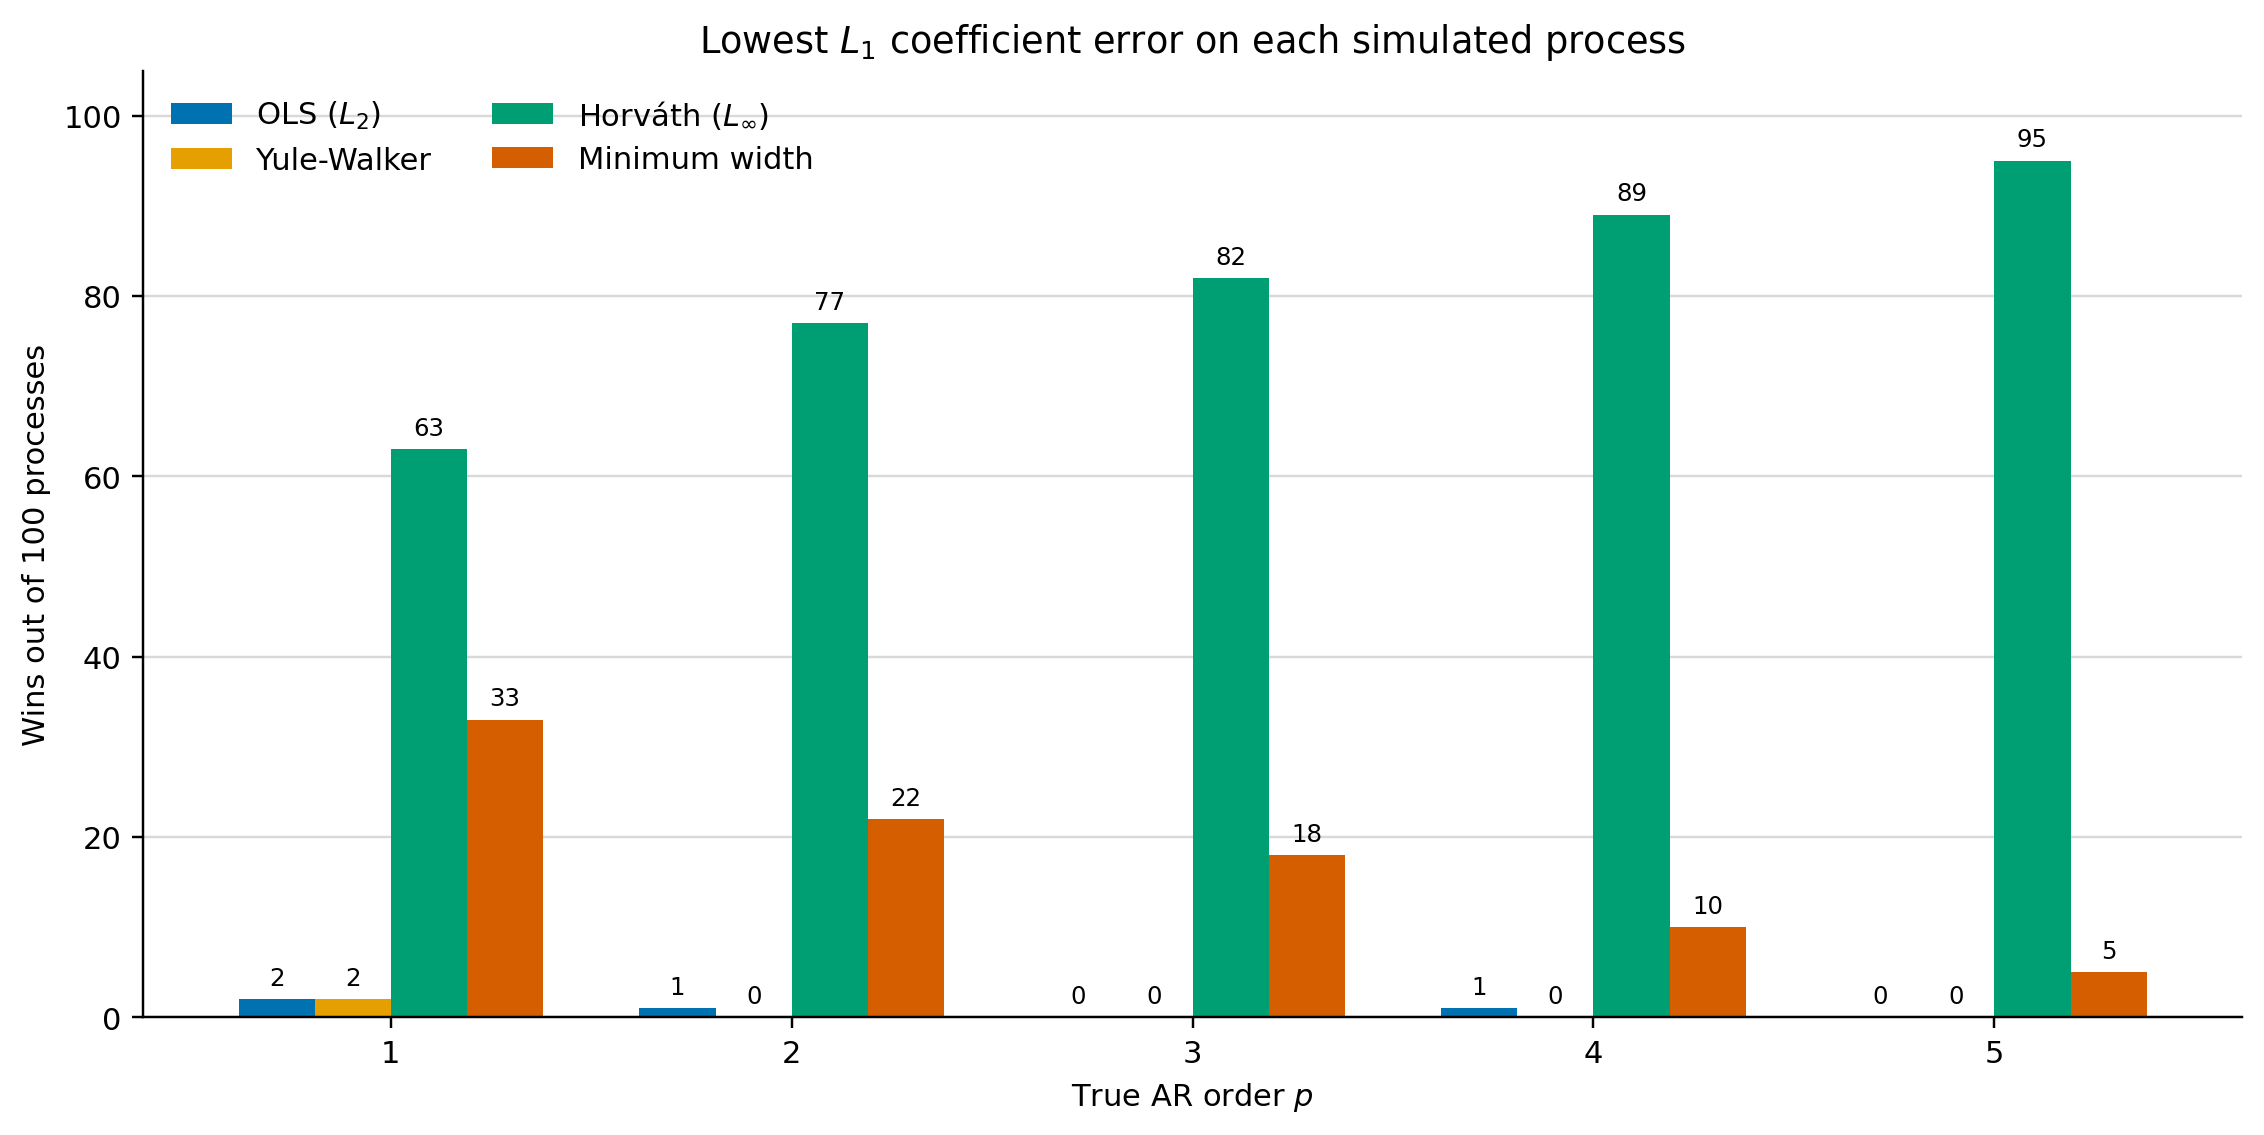

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Read the completed comparison; this cell does not simulate or fit processes.
comparison_data_dir = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            root / "Code" / "Code_AR_processes" / "outputs" / "csv"
            / "ar3_minimum_width_k4" / "four_method_comparison",
            root / "outputs" / "csv" / "ar3_minimum_width_k4"
            / "four_method_comparison",
        )
        if (candidate / "per_process_estimates.csv").is_file()
    ),
    None,
)
if comparison_data_dir is None:
    raise FileNotFoundError("Run the four-method experiment before plotting.")

per_process_results = pd.read_csv(comparison_data_dir / "per_process_estimates.csv")
methods = ["OLS (L2)", "Yule-Walker", "Horváth (L∞)", "Minimum width"]
orders = [1, 2, 3, 4, 5]
errors_by_process = per_process_results.pivot(
    index=["order", "replication"], columns="method", values="l1_error"
).reindex(columns=methods)
if (
    errors_by_process.shape != (500, 4)
    or errors_by_process.isna().any().any()
    or not errors_by_process.groupby(level="order").size().eq(100).all()
):
    raise ValueError("Expected four errors for each of 100 processes at each order.")

best_error = errors_by_process.min(axis=1)
tie_counts = errors_by_process.eq(best_error, axis=0).sum(axis=1)
if not tie_counts.eq(1).all():
    raise ValueError("A process has tied best methods; decide a tie rule first.")
best_method = errors_by_process.idxmin(axis=1).rename("best_method")
winner_counts = (
    best_method.reset_index()
    .groupby(["order", "best_method"]).size()
    .unstack(fill_value=0)
    .reindex(index=orders, columns=methods, fill_value=0)
)
assert winner_counts.sum(axis=1).eq(100).all()
winner_counts.rename_axis("order").to_csv(comparison_data_dir / "winner_counts.csv")

colors = {
    "OLS (L2)": "#0072B2",
    "Yule-Walker": "#E69F00",
    "Horváth (L∞)": "#009E73",
    "Minimum width": "#D55E00",
}
fig, axis = plt.subplots(figsize=(10.4, 5.3))
positions = np.arange(len(orders), dtype=float)
bar_width = 0.19
for method_index, method in enumerate(methods):
    counts = winner_counts[method].to_numpy()
    bars = axis.bar(
        positions + (method_index - 1.5) * bar_width,
        counts,
        width=bar_width,
        color=colors[method],
        label={"OLS (L2)": r"OLS ($L_2$)", "Horváth (L∞)": r"Horváth ($L_\infty$)"}.get(method, method),
    )
    axis.bar_label(bars, labels=[str(count) for count in counts],
                   padding=3, fontsize=8)

axis.set(
    title="Lowest $L_1$ coefficient error on each simulated process",
    xlabel="True AR order $p$",
    ylabel="Wins out of 100 processes",
    xticks=positions,
    xticklabels=[str(order) for order in orders],
    ylim=(0, 105),
)
axis.set_yticks(np.arange(0, 101, 20))
axis.grid(axis="y", color="0.85", linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[["top", "right"]].set_visible(False)
axis.legend(loc="upper left", ncol=2, frameon=False)
fig.tight_layout()

figure_name = "best_method_frequency_by_order"
outputs_dir = comparison_data_dir.parents[2]
png_dir = outputs_dir / "images" / "ar3_minimum_width_k4"
pdf_dir = outputs_dir / "pdfs" / "ar3_minimum_width_k4"
png_dir.mkdir(parents=True, exist_ok=True)
pdf_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(png_dir / f"{figure_name}.png", dpi=220, bbox_inches="tight")
fig.savefig(pdf_dir / f"{figure_name}.pdf", bbox_inches="tight")
plt.show()
